# 02 · Elección de variantes y resultado en el test

Lee de MLflow la última ejecución de `python -m ml.evaluar`:

1. **Validación:** las 20 variantes, la elegida de cada familia y la ganadora.
2. **Test:** las tres elegidas frente a la popularidad, con IC 95 %.
3. **Errores:** cómo cambia el acierto según cuántas notas tiene el usuario.

Hace falta MLflow arrancado (`docker compose up -d`) y haber ejecutado `python -m ml.evaluar`.

In [1]:
import sys
from pathlib import Path

# Raíz del repositorio en el path, para importar ml y pipeline desde notebooks/
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import os

os.environ.setdefault("MLFLOW_DISABLE_TELEMETRY", "true")
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")

import mlflow
import numpy as np
import pandas as pd
from dotenv import load_dotenv

load_dotenv(RAIZ / ".env")
mlflow.set_tracking_uri(os.environ.get("MLFLOW_TRACKING_URI", "http://localhost:5000"))

from ml.evaluar import EXPERIMENTO_TEST, EXPERIMENTO_VALIDACION


# Lote que se analiza: None = la última evaluación completa (con todos los usuarios).
# Para fijar el de la memoria: LOTE = "20261120-190950"
LOTE = None


def ejecuciones(experimento: str, lote: str | None = None) -> tuple[pd.DataFrame, str]:
    """Ejecuciones completas de un lote (por defecto, el más reciente) como tabla, y su lote.
    Las pruebas con --usuarios no cuentan."""
    runs = mlflow.search_runs(experiment_names=[experimento], order_by=["attributes.start_time DESC"])
    if "params.muestra_usuarios" in runs:
        runs = runs[runs["params.muestra_usuarios"] == "todos"]
    if runs.empty:
        raise ValueError(f"No hay ejecuciones completas en {experimento}: ejecuta python -m ml.evaluar")
    lote = lote or runs["tags.lote"].iloc[0]
    runs = runs[runs["tags.lote"] == lote].copy()
    if runs.empty:
        raise ValueError(f"El lote {lote} no está en {experimento}")
    runs.columns = [c.split(".", 1)[1] if c.startswith(("metrics.", "params.", "tags.")) else c
                    for c in runs.columns]
    runs = runs.loc[:, ~runs.columns.duplicated()]   # "familia" es parámetro y etiqueta a la vez
    usuarios = f"{int(runs['usuarios_evaluados'].iloc[0]):,}".replace(",", ".")
    print(f"{experimento}: lote {lote}, {len(runs)} ejecuciones, datos: {runs['datos'].iloc[0]}, "
          f"usuarios evaluados: {usuarios}")
    return runs, lote

c:\Users\ferlo\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import matplotlib.pyplot as plt

# Colores y estilo comunes de las figuras
SERIE = ["#2a78d6", "#eb6834", "#1baf7a"]          # azul, naranja, aguamarina
TEXTO, TEXTO_2, REJILLA, FONDO = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "axes.edgecolor": REJILLA,
    "axes.labelcolor": TEXTO_2, "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "text.color": TEXTO, "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "lines.linewidth": 2, "lines.markersize": 8,
})

## 1. Validación

Cada variante se entrenó con la parte de **ajuste** (64 %) y se midió en la de **validación**
(16 %). De cada familia se elige la de mayor NDCG@10 (`elegida`), y la mejor de las tres es
la `ganadora`: la que va a producción.

In [3]:
val, lote = ejecuciones(EXPERIMENTO_VALIDACION, LOTE)
val["vecinos"] = pd.to_numeric(val.get("vecinos"), errors="coerce").astype("Int64")
columnas = ["familia", "criterio", "rasgos", "variante", "vecinos", "ndcg_10", "ndcg_10_ic_inf",
            "ndcg_10_ic_sup", "cobertura", "elegida", "ganadora"]
tabla_val = (val.reindex(columns=columnas).sort_values(["familia", "ndcg_10"], ascending=[True, False])
             .fillna({"criterio": "", "rasgos": "", "variante": "", "elegida": "", "ganadora": ""})
             .reset_index(drop=True))
tabla_val.round(4)

seleccion_en_validacion: lote 20261120-190950, 20 ejecuciones, datos: bronze, usuarios evaluados: 221.726


,familia,criterio,rasgos,variante,vecinos,ndcg_10,ndcg_10_ic_inf,ndcg_10_ic_sup,cobertura,elegida,ganadora
0,contenido,,etiquetas+numericos+descripcion,binaria,100,0.0204,0.0201,0.0207,0.6882,si,
1,contenido,,etiquetas+numericos+descripcion,centrada,100,0.0201,0.0199,0.0204,0.8343,,
2,contenido,,etiquetas,centrada,100,0.0170,0.0168,0.0173,0.8783,,
3,contenido,,etiquetas+numericos,centrada,100,0.0164,0.0161,0.0167,0.8338,,
4,contenido,,etiquetas+numericos,binaria,100,0.0159,0.0157,0.0162,0.6795,,
5,contenido,,etiquetas,binaria,100,0.0154,0.0152,0.0157,0.7727,,
6,item_knn,,,binaria,10,0.1416,0.1408,0.1423,0.2994,si,si
7,item_knn,,,binaria,25,0.1407,0.1400,0.1415,0.2703,,
8,item_knn,,,binaria,400,0.1401,0.1393,0.1409,0.2223,,
9,item_knn,,,binaria,50,0.1386,0.1379,0.1394,0.2517,,


### Item-kNN: variante y número de vecinos

Las bandas son el IC 95 % por bootstrap de cada punto. Si dos puntos tienen bandas que se
solapan mucho, la diferencia entre ellos es pequeña frente al ruido de la medida.

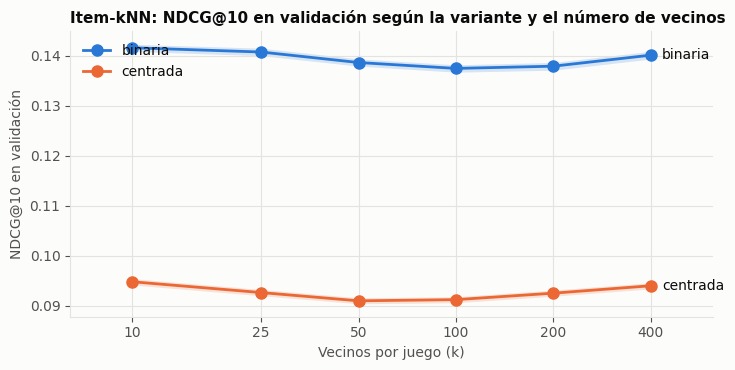

In [4]:
knn = val[val["familia"] == "item_knn"].sort_values("vecinos")
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for color, variante in zip(SERIE, ["binaria", "centrada"]):
    d = knn[knn["variante"] == variante]
    if d.empty:
        continue
    ax.fill_between(d["vecinos"], d["ndcg_10_ic_inf"], d["ndcg_10_ic_sup"], color=color,
                    alpha=0.18, linewidth=0)
    ax.plot(d["vecinos"], d["ndcg_10"], color=color, marker="o", label=variante)
    ax.annotate(variante, (d["vecinos"].iloc[-1], d["ndcg_10"].iloc[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", color=TEXTO)
ax.set_xscale("log")
ax.xaxis.set_minor_locator(plt.NullLocator())
ax.set_xticks(sorted(knn["vecinos"].unique()))
ax.set_xticklabels([str(int(k)) for k in sorted(knn["vecinos"].unique())])
ax.set_xlabel("Vecinos por juego (k)")
ax.set_ylabel("NDCG@10 en validación")
ax.set_title("Item-kNN: NDCG@10 en validación según la variante y el número de vecinos")
ax.legend(loc="upper left")
ax.margins(x=0.12)
plt.tight_layout()
plt.show()

In [5]:
# Elegidas y distancia a la segunda mejor de su familia
for familia, d in val.sort_values("ndcg_10", ascending=False).groupby("familia", sort=False):
    primera, segunda = d.iloc[0], (d.iloc[1] if len(d) > 1 else None)
    texto = f"{familia:12s} elegida: {primera['mlflow.runName'] if 'mlflow.runName' in d else ''}"
    texto += f"  NDCG@10 {primera['ndcg_10']:.4f}"
    if segunda is not None:
        texto += f"  (segunda: {segunda['ndcg_10']:.4f}, diferencia {primera['ndcg_10'] - segunda['ndcg_10']:+.4f})"
    print(texto)
print()
print("Ganadora:", val.loc[val["ganadora"] == "si", "mlflow.runName"].iloc[0])

item_knn     elegida: item_knn-binaria-k10  NDCG@10 0.1416  (segunda: 0.1407, diferencia +0.0008)
popularidad  elegida: popularidad-valoraciones  NDCG@10 0.1024  (segunda: 0.1023, diferencia +0.0001)
contenido    elegida: contenido-etiquetas+numericos+descripcion-binaria-k100  NDCG@10 0.0204  (segunda: 0.0201, diferencia +0.0002)

Ganadora: item_knn-binaria-k10


### Decisión sobre el número de vecinos

La rejilla empezó en 25 vecinos. Como ganó el extremo (25), se amplió a 10, y volvió a ganar el
extremo (10). Se decidió **no bajar más** (21/11/2026):

- entre 10 y 25 vecinos el NDCG@10 cambia menos de 0,001, con intervalos que se solapan, frente
  a una ventaja de más de 0,05 sobre la popularidad;
- con menos vecinos, los usuarios con pocas notas apenas tendrían juegos candidatos.

Por eso, si el mejor item-kNN usa 10 vecinos, `ml/evaluar.py` lo anota como límite decidido y no
como aviso.

## 2. Test

Las tres elegidas se entrenaron de nuevo con ajuste + validación (80 %) y se midieron **una
vez** en el test (20 %). La columna `dif_ndcg_10` es la diferencia pareada con la popularidad:
cada usuario se compara consigo mismo, y si su IC no incluye el 0, la diferencia no es ruido.

**El techo.** Muchos usuarios tienen menos de 10 juegos relevantes en el test, así que ni una
lista perfecta llega a precision@10 = 1. `precision_10_maxima` y `recall_10_maximo` dicen lo que
sacaría esa lista perfecta: las cifras de los modelos se leen frente a ellas.

In [6]:
test, _ = ejecuciones(EXPERIMENTO_TEST, lote)     # el mismo lote que la validación
orden = {"popularidad": 0, "contenido": 1, "item_knn": 2}
test = test.sort_values("familia", key=lambda s: s.map(orden))
columnas = ["mlflow.runName", "ganadora", "precision_10", "recall_10", "ndcg_10", "ndcg_10_ic_inf",
            "ndcg_10_ic_sup", "dif_ndcg_10", "dif_ndcg_10_ic_inf", "dif_ndcg_10_ic_sup", "cobertura"]
(test.reindex(columns=columnas).rename(columns={"mlflow.runName": "modelo"})
 .fillna({"ganadora": ""}).round(4))

evaluacion_en_test: lote 20261120-190950, 3 ejecuciones, datos: bronze, usuarios evaluados: 222.771


,modelo,ganadora,precision_10,recall_10,ndcg_10,ndcg_10_ic_inf,ndcg_10_ic_sup,dif_ndcg_10,dif_ndcg_10_ic_inf,dif_ndcg_10_ic_sup,cobertura
2,popularidad-valoraciones,,0.0919,0.1101,0.1318,0.1311,0.1325,NaN,NaN,NaN,0.0034
1,contenido-etiquetas+numericos+descripcion-bina...,,0.0177,0.0222,0.0248,0.0245,0.0251,-0.1070,-0.1077,-0.1062,0.6449
0,item_knn-binaria-k10,si,0.1289,0.1582,0.1885,0.1877,0.1894,0.0567,0.0561,0.0574,0.2694


In [7]:
if "precision_10_maxima" in test:
    techo = test.iloc[0]
    print(f"Con una lista perfecta: precision@10 = {techo['precision_10_maxima']:.3f}, "
          f"recall@10 = {techo['recall_10_maximo']:.3f}")
    for _, fila in test.iterrows():
        print(f"{fila['familia']:12s} alcanza el {100 * fila['precision_10'] / techo['precision_10_maxima']:.0f} % "
              f"de la precision@10 posible y el {100 * fila['recall_10'] / techo['recall_10_maximo']:.0f} % "
              "del recall@10 posible")
else:
    print("Este lote es anterior al cálculo del techo: vuelve a ejecutar python -m ml.evaluar --fase test")

Con una lista perfecta: precision@10 = 0.617, recall@10 = 0.859
popularidad  alcanza el 15 % de la precision@10 posible y el 13 % del recall@10 posible
contenido    alcanza el 3 % de la precision@10 posible y el 3 % del recall@10 posible
item_knn     alcanza el 21 % de la precision@10 posible y el 18 % del recall@10 posible


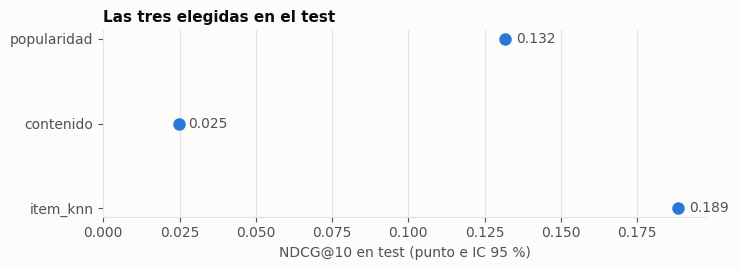

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 2.8))
y = np.arange(len(test))[::-1]
ax.errorbar(test["ndcg_10"], y, xerr=[test["ndcg_10"] - test["ndcg_10_ic_inf"],
                                       test["ndcg_10_ic_sup"] - test["ndcg_10"]],
            fmt="o", color=SERIE[0], ecolor=SERIE[0], elinewidth=2, capsize=0)
for yi, (_, fila) in zip(y, test.iterrows()):
    ax.annotate(f"{fila['ndcg_10']:.3f}", (fila["ndcg_10_ic_sup"], yi), xytext=(6, 0),
                textcoords="offset points", va="center", color=TEXTO_2)
ax.set_yticks(y)
ax.set_yticklabels(test["familia"])
ax.set_xlim(left=0)
ax.set_xlabel("NDCG@10 en test (punto e IC 95 %)")
ax.set_title("Las tres elegidas en el test")
ax.grid(axis="y", visible=False)
ax.margins(x=0.15)
plt.tight_layout()
plt.show()

## 3. Errores: usuarios con pocas o muchas notas

Cada ejecución del test guarda `metricas_por_usuario.parquet` (sin identificadores), con el
número de notas que el modelo veía de cada usuario. Sirve para saber cómo funcionará con
alguien de la app que solo ha metido unos pocos juegos.

In [9]:
grupos = [0, 15, 30, 60, 150, np.inf]
etiquetas = ["<= 15", "16-30", "31-60", "61-150", "> 150"]
filas = []
for _, run in test.iterrows():
    ruta = mlflow.artifacts.download_artifacts(run_id=run["run_id"],
                                               artifact_path="metricas_por_usuario.parquet")
    m = pd.read_parquet(ruta)
    m["notas_vistas"] = pd.cut(m["n_valoraciones_entrada"], grupos, labels=etiquetas)
    filas.append(m.groupby("notas_vistas", observed=False)["ndcg"].mean().rename(run["familia"]))
por_actividad = pd.concat(filas, axis=1)
por_actividad["usuarios"] = m.groupby("notas_vistas", observed=False).size()
por_actividad.round(4)

,popularidad,contenido,item_knn,usuarios
notas_vistas,,,,
<= 15,0.0907,0.0221,0.1381,54125
16-30,0.1031,0.0204,0.1501,55483
31-60,0.1138,0.0200,0.1640,48857
61-150,0.1604,0.0266,0.2269,42352
> 150,0.2905,0.0497,0.3904,21954


In [10]:
if {"item_knn", "popularidad"} <= set(por_actividad.columns):
    for grupo, fila in por_actividad.iterrows():
        usuarios = f"{int(fila['usuarios']):,}".replace(",", ".")
        print(f"{grupo:>7} notas vistas: item-kNN {fila['item_knn']:.3f}, popularidad "
              f"{fila['popularidad']:.3f}, diferencia {fila['item_knn'] - fila['popularidad']:+.3f} "
              f"({usuarios} usuarios)")

  <= 15 notas vistas: item-kNN 0.138, popularidad 0.091, diferencia +0.047 (54.125 usuarios)
  16-30 notas vistas: item-kNN 0.150, popularidad 0.103, diferencia +0.047 (55.483 usuarios)
  31-60 notas vistas: item-kNN 0.164, popularidad 0.114, diferencia +0.050 (48.857 usuarios)
 61-150 notas vistas: item-kNN 0.227, popularidad 0.160, diferencia +0.066 (42.352 usuarios)
  > 150 notas vistas: item-kNN 0.390, popularidad 0.291, diferencia +0.100 (21.954 usuarios)


## Lectura (lote 20261120-190950)

**Validación** (221.726 usuarios evaluados)

- **El item-kNN binario es la mejor familia y la ganadora.** Con 10 vecinos saca NDCG@10 = 0,1416
  (IC 0,1408-0,1423). La curva según el número de vecinos es casi plana: entre el mejor (10) y el
  peor (100, 0,1375) hay 0,004.
- **La variante binaria gana a la centrada con cualquier número de vecinos** (0,14 frente a 0,09).
  En BGG, haber valorado un juego dice más de los gustos que la nota concreta.
- **Los dos criterios de popularidad empatan** (0,1024 y 0,1023).
- **El modelo por contenido queda por debajo de la popularidad.** Su mejor versión (etiquetas,
  numéricos y descripción) saca 0,0204, aunque recomienda mucho más catálogo (68-88 %). Las
  mecánicas y los temas, por sí solos, no predicen qué juegos valorará alguien.

**Test** (222.771 usuarios evaluados)

- **El item-kNN supera a la popularidad:** NDCG@10 = 0,1885 frente a 0,1318. La diferencia pareada
  es +0,0567, con IC 95 % de 0,0561 a 0,0574: el intervalo está lejos del 0.
- **precision@10 = 0,129 y recall@10 = 0,158.** Se leen frente a su techo: con una mediana de 6
  relevantes reservados por usuario, una lista perfecta sacaría 0,617 y 0,859. Además, un juego
  que el usuario no ha valorado cuenta como fallo aunque le pudiera gustar.
- **Cobertura:** el item-kNN recomienda el 27 % del catálogo; la popularidad, el 0,3 %.
- **El test confirma la elección:** el item-kNN, elegido en validación, también es el mejor en test.

**Usuarios con pocas notas:** la tabla y el resumen de la sección 3 dicen cuánto baja el acierto
cuando el modelo ve pocos juegos de una persona, que es el caso de alguien nuevo en la app.